# Phase II, Pair 1: question F — neighbouring points

*Can information from neighbouring points change the forecast, in which form must it be given, and what does the model do with it?*

| Authors | Sandro Müller K52010874 |
|---|---|
| Status | done |


Phase I bascially opened up this question, checkout Exp 3, 4 and 5 (pressure, a warning flag and neighbours as extra inputs did not improve the drop captured) to understand why.

## 1 · Question

Can information from neighbouring points change the forecast, in which form must it be given, and what does the model do with it?

## 2 · Why this question

In Phase I, TiRex-2 forecast each point from its own history only. When we gave it more inputs (pressure, a front flag, neighbouring and upstream points), the share of the temperature drop it captured stayed at about 21 %. 

**We do not know why** 

After some thinking we have come up with 3 explanations: 

1. the model might not see the extra rows at all,
2. it might see them but not use them,
3. or we might have given them in a form the model cannot use. 

TiRex-2 accepts neighbours in three different ways (as extra targets, as past-only covariates, as future-known covariates), and Phase I mostly used past-only channels.

## 3 · Hypothesis and what would count as an answer

**Hypothesis.**

- **H1.** Past-only neighbour channels are ignored, as in Phase I.
- **H2.** Neighbors given as future covariates (shifted by at least the horizon, so no leakage happens) improve the forecast.
- **H3** Neighbors given as extra targets improve the forecast, because attend to each other in every block.

This hypothesis are the main idea to answer the question and to say for sure if spatial information can be used to make TiRex-2 better in predicting cold fronts.

Each hypothesis is tested and answered in its own part of section 8: [H1](#h1) · [H2](#h2) · [H3](#h3).

## 4 · Setup

The code cell below holds the imports, paths and model loading. First, what the model source says about neighbours.

### What the source says about neighbours

*Read in `tirex2.py`, version `tirex-2==0.3.1` (pinned in `requirements.txt`) and `main` of `github.com/NX-AI/tirex-2`.*

**1 · How the input is grouped**

- `PostProcessor.transform_input` packs every `TimeseriesType` of the batch into **one group**, in this order: target rows, past covariates, future covariates.
- It returns `x` (one row per variate), `group_vector` (group id per row) and `target_mask` (True for target rows).
- `TiRex2._prepare_forward` then sets `known_covariate_mask` = "has a value in the last `future_len` steps and is not a target". So future covariates are *known*; past covariates (NaN in the future part) are not.

**2 · Which rows go where**

`variate_indices(group_vector, target_mask, known_covariate_mask)` is computed once per forward pass (in `main`; 0.3.1 computes the same inside the blocks).

| Row type | Reverse (backward-in-time) xLSTM cell | Variate attention |
|---|---|---|
| Target | no, forward only | yes, if its group has more than one row |
| Past covariate | no, forward only | yes |
| Future (known) covariate | **yes** | yes |

- A lone univariate series skips the variate attention.
- Without a `known_covariate_mask`, all non-targets go through the reverse cell.

**3 · Do several targets exchange information?** Yes.

Each `MultivariateBlock` runs the time mixer on every row on its own, then the `variate_mixer` (an `AttentionBlock` over the rows of each group, at every token position). The attention mask is `same_group & ~(covariate → target)`:

| Who looks at whom | Allowed? |
|---|---|
| a row of another group (another sample in the batch) | never |
| a covariate looking at a target | no |
| a target looking at any row of its group, including other targets | **yes** |

What this means for the forms in section 5:

- **Extra targets in one `TimeseriesType`** (`i_targets`, H3) are mixed with the point in every block. They are not just batched, so H3 can work in principle.
- **Separate `TimeseriesType`s** (as in `run_forecasts.py`) are only batched and never mix.

**4 · Side effects to keep in mind**

- Each target row is scaled on its own and, if `tta_diff` finds a trend, differenced on its own.
- With `tta_sign_flip`, the whole forecast runs a second time on the negated input and the two are averaged.

**5 · How to pass the inputs to `forecast()`**

```python
ts = TimeseriesType(
    target=...,             # [n_targets, T]
    past_covariates=...,    # [n_past, T] or None
    future_covariates=...,  # [n_fut, >= T + H] or None; anything longer than T + H is cut
)
out = model.forecast([ts, ...], prediction_length=H, output_type="numpy")
# each output: [n_targets, 9 quantiles, H]; row 0 is our point
```

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from tirex2 import TimeseriesType, load_model

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA = Path(os.environ.get("AIVIS_DATA", ROOT / "data" / "austria_15km"))
CKPT = os.environ.get("TIREX_CKPT", "NX-AI/TiRex-2")  # a local folder works too
DEVICE = os.environ.get("TIREX_DEVICE", "cpu")
RESULTS = ROOT / "data" / "notebooks" / "results" / "06_question_f"
RESULTS.mkdir(parents=True, exist_ok=True)

CONTEXT, HORIZON = 672, 24  # Phase I design: 28 days of history, 24 h forecast
QUANTILES = np.arange(1, 10) / 10
SEED = 0

model = load_model(CKPT, device=DEVICE)  # as in phase1-model-behavior/pair-1/run_forecasts.py
core = model.model  # the TiRex2 backbone
print(
    "input_patch_size",
    core.input_patch_size,
    "| blocks",
    len(core.stack),
    "| context_len",
    core.context_len,
    "| future_len",
    core.future_len,
    "| tta_sign_flip",
    core.tta_sign_flip,
    "| tta_diff",
    core.tta_diff,
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

input_patch_size 32 | blocks 12 | context_len 2048 | future_len 320 | tta_sign_flip False | tta_diff True


## 5 · Data

Austria 15 km dataset (378 points, hourly, 2025-10-01 → 2026-10-01). Same design as Phase I: 672 h context, 24 h horizon,
the context filled exactly as in `run_forecasts.py`; forecasts are scored against the observed (unfilled) temperature.

**Cases.** The start times are taken from the Phase I file `tirex2_forecasts.npz`, so the baseline can be checked against
Phase I: `N_GRID` grid starts spread over the year (seeded) and **all** front starts (front-12, front-6). The points are
`N_POINTS` interior points (all four lattice neighbours present), spread over Austria by farthest-point sampling. Every
form runs on exactly these start × point cases, not on the full 336 × 378 (Phase I needed about 75 minutes for that).

**Neighbours** (from `points_with_labels.csv`, Austria Lambert x/y in metres):
- *nearest*: the 4 lattice neighbours within 16 km (N, S, E, W);
- *upwind*: per case, from the mean wind (`UU`, `VV`) at the point over the last 6 h of the context, the up to 3 nearest
  points within 60 km that lie within ±35° of the direction the wind comes from. The travel time is distance / wind speed.
  With wind below 1 m/s, or no point in the sector, the 3 nearest points are used and the case is flagged.

Sample size: about 12 grid + 30 front starts × 10 points ≈ 400 cases per form. Gains are reported with a bootstrap over
start times (cases of one start are not independent).

In [2]:
# ---- Settings (change them here) -------------------------------------------
N_GRID = 12  # how many normal ("grid") start times; all front starts are used on top of these
N_POINTS = 10  # how many forecast points
K_NEAR, NEAR_KM = 4, 16  # nearest neighbours: up to 4 points within 16 km
K_UP, UP_KM = 3, 60  # upwind neighbours: up to 3 points within 60 km
UP_HALF_ANGLE = 35  # upwind sector: +-35 degrees around the direction the wind comes from
WIND_HOURS = 6  # the wind is the mean over the last 6 hours before the forecast start
MIN_WIND = 1.0  # m/s; with less wind we cannot say where the air comes from

# ---- Load the data ---------------------------------------------------------
pts = pd.read_csv(DATA / "points_with_labels.csv").set_index("point_id")  # coordinates of the points
grid = pd.read_parquet(DATA / "grid_long.parquet")  # hourly values: one row per point and hour


def fill_gaps(table):
    """Fill gaps inside a series by interpolation, and gaps at the ends with the nearest value."""
    return table.interpolate(limit_area="inside").ffill().bfill()


OBS = grid.pivot(index="time", columns="point_id", values="T2M")  # observed temperature, with gaps (for scoring)
T = fill_gaps(OBS)  # gaps filled (for the model input, as in run_forecasts.py)
times, pids = T.index, T.columns.to_numpy()
pts = pts.loc[pids]  # same point order as the columns of T
SER = T.to_numpy(np.float32).copy()  # the temperature as a plain array: SER[hour, point]

# The wind is only needed to find the upwind points. Without wind data we assume a westerly wind.
HAS_WIND = {"UU", "VV"} <= set(grid.columns)
if HAS_WIND:
    UU = fill_gaps(grid.pivot(index="time", columns="point_id", values="UU").reindex(times)).to_numpy(np.float32)
    VV = fill_gaps(grid.pivot(index="time", columns="point_id", values="VV").reindex(times)).to_numpy(np.float32)
else:
    print("No UU/VV in grid_long.parquet: upwind falls back to a westerly wind (from 270°)")

# Position of every point in km, and the distance between every two points
XY = pts[["x", "y"]].to_numpy(float) / 1000
DIST = np.linalg.norm(XY[:, None] - XY[None], axis=-1)  # DIST[a, b] = distance from point a to point b in km


# ---- Find the neighbours of a point ----------------------------------------
def nearest(j, k=K_NEAR, max_km=NEAR_KM):
    """The k points closest to point j (not j itself) that are at most max_km away."""
    by_distance = np.argsort(DIST[j])
    close = [i for i in by_distance if i != j and DIST[j, i] <= max_km]
    return close[:k]


def upwind(j, i):
    """Upwind neighbours of point j for a forecast that starts at hour i (only hours before i are used).
    Returns: the neighbours, their travel times in hours, the wind speed, and whether we had to fall back."""
    # wind at the point: mean over the last WIND_HOURS before the start
    if HAS_WIND:
        u = UU[i - WIND_HOURS : i, j].mean()
        v = VV[i - WIND_HOURS : i, j].mean()
    else:
        u, v = 3.0, 0.0
    speed = float(np.hypot(u, v))  # m/s

    if speed >= MIN_WIND:
        wind_from = -np.array([u, v]) / speed  # unit vector: the direction the air comes from
        offset = XY - XY[j]  # vector from point j to every other point
        dist = np.linalg.norm(offset, axis=1)
        cos_angle = (offset @ wind_from) / np.maximum(dist, 1e-9)  # 1 = straight upwind, 0 = sideways
        in_sector = (dist > 0) & (dist <= UP_KM) & (cos_angle >= np.cos(np.deg2rad(UP_HALF_ANGLE)))
        found = np.where(in_sector)[0]
        found = [int(p) for p in found[np.argsort(dist[in_sector])]][:K_UP]  # the closest ones first
        if found:
            travel = [int(np.ceil(DIST[j, p] / (speed * 3.6))) for p in found]  # hours = km / (km/h)
            return found, travel, speed, False

    # no usable wind, or no point in the sector: use the nearest points instead and mark the case
    found = nearest(j, K_UP, UP_KM)
    return found, [HORIZON] * len(found), speed, True


# ---- Choose the start times ------------------------------------------------
# We take the start times of the Phase I forecasts, so the baseline can be checked against Phase I.
P1 = np.load(DATA / "tirex2_forecasts.npz", allow_pickle=True)
p1_col = {p: k for k, p in enumerate(P1["pids"])}  # point id -> column in the Phase I arrays
tags = P1["tags"].astype(str)  # "grid", "front-12", "front-6", ...
rng = np.random.default_rng(SEED)

grid_k = np.where(tags == "grid")[0]  # all normal starts of Phase I ...
grid_k = np.sort(rng.choice(grid_k, size=min(N_GRID, len(grid_k)), replace=False))  # ... of which we draw N_GRID
front_k = np.where(np.char.startswith(tags, "front"))[0]  # all front starts

starts = []  # (hour index of the start, tag, row in the Phase I arrays)
for k in np.r_[grid_k, front_k]:
    origin = int(P1["origin_idx"][k])
    has_context = origin >= CONTEXT  # enough hours before the start
    has_truth = origin + HORIZON <= len(times)  # enough hours after it to score the forecast
    if has_context and has_truth:
        starts.append((origin, str(P1["tags"][k]), int(k)))

# ---- Choose the points -----------------------------------------------------
# Only "interior" points (all four lattice neighbours exist), spread over Austria by farthest-point sampling:
# start with one random point, then keep adding the point that is farthest from all points chosen so far.
interior = [j for j in range(len(pids)) if len(nearest(j)) == K_NEAR]
chosen = [interior[int(rng.integers(len(interior)))]]
while len(chosen) < min(N_POINTS, len(interior)):
    dist_to_chosen = DIST[np.ix_(interior, chosen)].min(axis=1)  # for each interior point: distance to the closest chosen one
    chosen.append(interior[int(np.argmax(dist_to_chosen))])

# ---- One row per case = one start time at one point ------------------------
cases = []
for i, tag, k in starts:
    for j in chosen:
        up, travel, speed, fallback = upwind(j, i)
        cases.append(
            {
                "i": i,  # hour index of the forecast start
                "tag": tag,
                "p1_k": k,
                "j": j,  # column index of the point
                "pid": pids[j],
                "near": nearest(j),  # the 4 lattice neighbours
                "up": up,  # the upwind neighbours
                "travel": travel,  # their travel times in hours
                "wind": speed,
                "up_fallback": fallback,
                "front": tag.startswith("front"),
            }
        )
cases = pd.DataFrame(cases)
print(
    f"{len(starts)} starts ({len(grid_k)} grid, {len(starts) - len(grid_k)} front) x {len(chosen)} points = {len(cases)} cases;"
    f" upwind fallback in {cases.up_fallback.mean():.0%}; median travel time {np.median(np.concatenate(cases.travel.to_numpy())):.0f} h"
)

42 starts (12 grid, 30 front) x 10 points = 420 cases; upwind fallback in 37%; median travel time 6 h


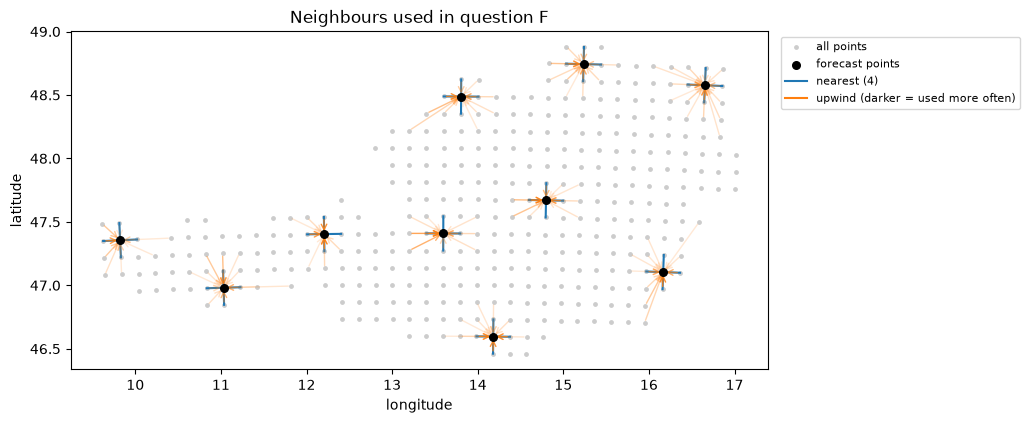

In [ ]:
# Map of the neighbours used: grey = all points, black = forecast points,
# blue lines = nearest neighbours, orange arrows = upwind neighbours (from the upwind point to the forecast point;
# darker = used at more start times)
fig, ax = plt.subplots(figsize=(9, 5.5))
lonlat = pts[["lon", "lat"]].to_numpy()
ax.scatter(pts.lon, pts.lat, s=6, c="0.8", label="all points")

# how often each upwind pair (point j, upwind point u) occurs over all cases
up_count = {}
for _, c in cases.iterrows():
    for u in c["up"]:
        up_count[(c["j"], u)] = up_count.get((c["j"], u), 0) + 1

n_starts = len(starts)
for (j, u), n in up_count.items():
    ax.annotate(
        "",
        xy=lonlat[j],  # the arrow points to the forecast point ...
        xytext=lonlat[u],  # ... and starts at the upwind point
        arrowprops={"arrowstyle": "->", "color": "tab:orange", "alpha": 0.15 + 0.85 * n / n_starts, "lw": 1},
    )

for j in chosen:  # the four nearest neighbours of each forecast point
    for nb in nearest(j):
        ax.plot(*lonlat[[j, nb]].T, color="tab:blue", lw=1.5)

ax.scatter(*lonlat[chosen].T, s=30, c="k", zorder=3, label="forecast points")
ax.plot([], [], color="tab:blue", label="nearest (4)")  # empty lines, only for the legend
ax.plot([], [], color="tab:orange", label="upwind (darker = used more often)")
ax.set(xlabel="longitude", ylabel="latitude", title="Neighbours used in question F")
ax.set_aspect(1 / np.cos(np.deg2rad(lonlat[:, 1].mean())))  # so that 1 degree east is not drawn longer than it is
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.savefig(RESULTS / "map_neighbours.png", dpi=150, bbox_inches="tight")

### Forms of neighbour information

All forms run on the same cases, only the `TimeseriesType` changes. The context of the point is always the 672 h before the forecast start `i`; an input series "shifted by `s`" has the value of the source at hour `τ - s` at hour `τ`.

| Form | Input | Uses data after `i`? | Hypothesis |
|---|---|---|---|
| `base` | the point alone | no | baseline |
| `p_past` | the 4 nearest neighbours as past-only covariates (the Phase I way) | no | H1 |
| `i_targets` | the 4 nearest neighbours as extra rows in `target` (forecast of row 0 is scored) | no | H3 |
| `ii_future` | the upwind points as future covariates, shifted by `max(travel time, 24 h)` | no (shift ≥ horizon) | H2 |
| `iii_features` | neighbour mean, spatial gradient (x, y), upwind difference as future covariates, shifted like `ii` | no | H2 |
| `leak_upper` | the upwind points unshifted, as future covariates: their real future values | **yes, upper bound only** | reference only |

The shift must be at least the horizon: with `s ≥ 24`, the newest value used at the last forecast hour `i + 23` is the source at `i - 1`. Hours before the start of the record are NaN (the model masks them).

In [4]:
def shifted(source, i, s, length):
    """Take `length` hours of one series, starting at the beginning of the context of start i, delayed by s hours.
    Delayed by s: at hour t the result holds the value that `source` had at hour t - s.
    Hours before the start of the record stay NaN (the model ignores NaN)."""
    hours = np.arange(i - CONTEXT, i - CONTEXT + length) - s  # which source hour goes into each position
    out = np.full(length, np.nan, np.float32)
    exists = (hours >= 0) & (hours < len(source))
    out[exists] = source[hours[exists]]
    if s >= HORIZON:
        # leakage rule: with a delay of at least the horizon, nothing from the forecast start on is used
        assert hours.max() <= i - 1
    return out


def features(c):
    """Engineered neighbour features over the whole time axis (4 rows):
    neighbour mean, temperature gradient in x and y (°C per 100 km), upwind difference."""
    j, near, up = c["j"], list(c["near"]), list(c["up"])
    mean = SER[:, near].mean(axis=1)  # mean temperature of the 4 neighbours

    # gradient: fit a plane  T = a + gx * dx + gy * dy  through the point and its neighbours, at every hour
    points = [j, *near]
    design = np.c_[np.ones(len(points)), XY[points] - XY[j]]  # columns: 1, dx, dy
    coef = np.linalg.lstsq(design, SER[:, points].T, rcond=None)[0]
    gx, gy = coef[1] * 100, coef[2] * 100

    upwind_diff = SER[:, up].mean(axis=1) - SER[:, j]  # upwind points minus the point itself
    return np.stack([mean, gx, gy, upwind_diff]).astype(np.float32)


def build(c, form, null_offset=0):
    """The TimeseriesType of one case in one form (see the table above).
    null_offset > 0 takes the neighbour series from that many hours earlier (control: real values, wrong date)."""
    i, j = int(c["i"]), int(c["j"])
    near, up = list(c["near"]), list(c["up"])
    delay_up = [max(t, HORIZON) for t in c["travel"]]  # upwind delay: the travel time, but at least the horizon

    # the point itself: the 672 hours before the start, shape [1, CONTEXT]
    target = torch.from_numpy(SER[i - CONTEXT : i, j][None].copy())

    if form == "base":  # the point alone
        return TimeseriesType(target=target, past_covariates=None, future_covariates=None)

    if form == "p_past":  # the 4 nearest neighbours as past-only covariates
        rows = [shifted(SER[:, n], i, null_offset, CONTEXT) for n in near]
        return TimeseriesType(target=target, past_covariates=torch.from_numpy(np.stack(rows)), future_covariates=None)

    if form == "i_targets":  # the 4 nearest neighbours as extra target rows; row 0 stays the point
        rows = [SER[i - CONTEXT : i, j]] + [shifted(SER[:, n], i, null_offset, CONTEXT) for n in near]
        return TimeseriesType(target=torch.from_numpy(np.stack(rows)), past_covariates=None, future_covariates=None)

    if form == "ii_future":  # the upwind points as future covariates, delayed
        rows = [shifted(SER[:, u], i, d + null_offset, CONTEXT + HORIZON) for u, d in zip(up, delay_up)]
        return TimeseriesType(target=target, past_covariates=None, future_covariates=torch.from_numpy(np.stack(rows)))

    if form == "iii_features":  # mean, gradient x/y and upwind difference as future covariates, delayed
        f = features(c)
        delays = [HORIZON, HORIZON, HORIZON, max(delay_up)]  # the upwind difference uses the longest upwind delay
        rows = [shifted(f[k], i, delays[k] + null_offset, CONTEXT + HORIZON) for k in range(4)]
        return TimeseriesType(target=target, past_covariates=None, future_covariates=torch.from_numpy(np.stack(rows)))

    if form == "leak_upper":  # the upwind points NOT delayed: their real future values (upper bound only)
        rows = [shifted(SER[:, u], i, 0, CONTEXT + HORIZON) for u in up]
        return TimeseriesType(target=target, past_covariates=None, future_covariates=torch.from_numpy(np.stack(rows)))

    raise ValueError(form)


FORMS = ["base", "p_past", "i_targets", "ii_future", "iii_features", "leak_upper"]
NEIGHBOUR_FORMS = FORMS[1:]


def run_form(form, cases, batch_size=64):
    """Forecast all cases in one form. The result is saved, so a second run only loads it."""
    path = RESULTS / f"preds_{form}.npy"
    if path.exists():
        saved = np.load(path)
        if len(saved) == len(cases):  # only reuse it if it was made for the same cases
            return saved

    start = time.time()
    batch = [build(c, form) for c in cases.to_dict("records")]
    out = model.forecast(batch, prediction_length=HORIZON, output_type="numpy", batch_size=batch_size)
    preds = np.stack([f[0] for f in out]).astype(np.float32)  # row 0 = the point; shape [case, 9 quantiles, 24 h]
    np.save(path, preds)
    print(f"{form}: {len(cases)} cases in {time.time() - start:.0f}s")
    return preds


PRED = {form: run_form(form, cases) for form in FORMS}

## 6 · Technique 1 — skill gain

Per case: MAE of the median over the 24 forecast hours against the observed temperature, and the coverage of the 0.1–0.9 band (nominal 80 %). Gain = MAE(base) − MAE(form), so **positive = better than the point alone**. Mean gain per form, split by normal (grid) and front starts, with a 95 % bootstrap interval over start times.

*What it shows:* whether a form improves the forecast on average. *What it cannot show:* whether the model reads the neighbours at all; no gain can mean "ignored" or "seen but not used" (Technique 2 separates the two).

In [5]:
obs = np.stack([OBS.to_numpy(np.float32)[c.i : c.i + HORIZON, c.j] for c in cases.itertuples()])  # [case, 24]


def mae(p):
    return np.nanmean(np.abs(p[:, 4] - obs), axis=1)


def coverage(p):
    inside = (obs >= p[:, 0]) & (obs <= p[:, 8])
    return np.nanmean(np.where(np.isnan(obs), np.nan, inside.astype(float)), axis=1)


def boot_ci(values, groups, n=2000, seed=SEED):
    """95 % interval of the mean, resampling whole start times."""
    r = np.random.default_rng(seed)
    ug = np.unique(groups)
    by = [values[groups == g] for g in ug]
    means = [np.nanmean(np.concatenate([by[k] for k in r.integers(len(ug), size=len(ug))])) for _ in range(n)]
    return np.nanpercentile(means, [2.5, 97.5])


score = pd.DataFrame({"case": np.arange(len(cases)), "start": cases.i, "front": cases.front})
for f in FORMS:
    score[f"mae_{f}"], score[f"cov_{f}"] = mae(PRED[f]), coverage(PRED[f])

rows = []
for f in FORMS:
    for label, sel in [
        ("all", np.ones(len(cases), bool)),
        ("normal", ~cases.front.to_numpy()),
        ("front", cases.front.to_numpy()),
    ]:
        g = (score["mae_base"] - score[f"mae_{f}"]).to_numpy()[sel]
        lo, hi = boot_ci(g, score.start.to_numpy()[sel]) if f != "base" else (0.0, 0.0)
        rows.append(
            {
                "form": f,
                "starts": label,
                "n": int(sel.sum()),
                "mae": score[f"mae_{f}"][sel].mean(),
                "gain": np.nanmean(g),
                "gain_lo": lo,
                "gain_hi": hi,
                "coverage": score[f"cov_{f}"][sel].mean(),
            }
        )
gain = pd.DataFrame(rows)
gain.to_csv(RESULTS / "skill_gain.csv", index=False)
gain.round(3)

,form,starts,n,mae,gain,gain_lo,gain_hi,coverage
0,base,all,420,2.720,0.000,0.000,0.000,0.656
1,base,normal,120,1.676,0.000,0.000,0.000,0.815
2,base,front,300,3.138,0.000,0.000,0.000,0.593
3,p_past,all,420,2.756,-0.035,-0.061,-0.009,0.639
4,p_past,normal,120,1.686,-0.009,-0.054,0.026,0.802
5,p_past,front,300,3.183,-0.046,-0.076,-0.013,0.574
6,i_targets,all,420,2.755,-0.035,-0.060,-0.009,0.639
7,i_targets,normal,120,1.685,-0.009,-0.053,0.026,0.802
8,i_targets,front,300,3.183,-0.045,-0.075,-0.012,0.575
9,ii_future,all,420,2.829,-0.108,-0.231,0.005,0.548


## 7 · Technique 2 - does anything move?

Two internal measures, on a subset of cases (all front cases of `GRAD_POINTS` points plus as many grid cases):

- **Gradient** of the median forecast at hour `FORECAST_HOUR` with respect to every input row. Sensitivity of a form = summed |gradient| over the neighbour rows / summed |gradient| over the point's own context. For future covariates the
  context part and the forecast-window part are reported separately.
- **Hidden-state distance** between the run with neighbours and the baseline, per block: ‖h_form − h_base‖ / ‖h_base‖
  over all tokens of the point's row.

**Control.** The same forms with the neighbour series taken from 30 days earlier (real temperatures, wrong dates: `null`).
A form whose numbers are at the level of its control is ignored in practice.

**Reading:** gradients ≈ control and states unchanged → the model ignores that form. Gradients and states clearly above the control but no skill gain → the model sees the information but does not use it.

The two functions below are the Phase II helpers (`hidden_states`, `gradient`) widened to take a full `TimeseriesType`, so that gradients with respect to covariate and extra-target rows are available. The gradient uses a NaN-safe copy of the scaler (see section 12 for why). Swap in the shared helpers from `p2/pair1-model-helpers` once they accept covariates; the check in section 9 compares them with `model.forecast`.

In [6]:
import types

FORECAST_HOUR, GRAD_POINTS, NULL_OFFSET = 12, 4, 30 * 24


def _predict(ts_list, grad):
    """TiRex2.predict without the no_grad decorator (same sign-flip TTA)."""
    with torch.set_grad_enabled(grad):
        f = core._predict(ts_list, HORIZON, tta_diff=core.tta_diff, preserve_grad=grad)
        if core.tta_sign_flip:
            fl = core._predict(
                [core._sign_flip(t) for t in ts_list], HORIZON, tta_diff=core.tta_diff, preserve_grad=grad
            )
            comp = core._complement_indices().to(fl[0].device)
            f = [(a - b.index_select(1, comp)) / 2 for a, b in zip(f, fl)]
    return f


def hidden_states(ts):
    """Output of every block for the rows of one TimeseriesType, first (unflipped) pass: [blocks, rows, tokens, dim]."""
    out = []
    hooks = [b.register_forward_hook(lambda m, a, o: out.append(o[0].detach().cpu())) for b in core.stack]
    try:
        _predict([ts], grad=False)
    finally:
        for h in hooks:
            h.remove()
    return torch.stack(out[: len(core.stack)]).numpy()


def _nan_safe_scale(self, x):
    """Same values as Scaler.scale, but NaN padding never enters an operation that has a gradient.
    (With the original, arcsinh and the division backpropagate NaN from the padding into loc/scale and so into
    every input hour.)"""
    valid = ~torch.isnan(x)
    x0 = torch.where(valid, x, torch.zeros_like(x))
    n = valid.sum(-1, keepdim=True)
    loc = torch.where(n > 0, x0.sum(-1, keepdim=True) / n.clamp_min(1), torch.zeros_like(n, dtype=x.dtype))
    var = torch.where(valid, (x0 - loc) ** 2, torch.zeros_like(x)).sum(-1, keepdim=True) / n.clamp_min(1)
    scale = torch.where(n > 0, var.clamp_min(self.eps**2).sqrt(), torch.ones_like(var))
    is_binary = None
    if self.binaryaware:
        is_binary = ((x0 == 0.0) | (x0 == 1.0) | ~valid).all(dim=-1, keepdim=True)
        loc = torch.where(is_binary, torch.zeros_like(loc), loc)
        scale = torch.where(is_binary, torch.ones_like(scale), scale)
    scaled = (x0 - loc) / scale
    if self.use_arcsinh:
        scaled = (
            torch.where(is_binary, scaled, torch.arcsinh(scaled)) if is_binary is not None else torch.arcsinh(scaled)
        )
    return torch.where(valid, scaled, torch.full_like(scaled, float("nan"))), (loc, scale, is_binary)


class nan_safe_scaler:
    def __enter__(self):
        core.scaler.scale = types.MethodType(_nan_safe_scale, core.scaler)

    def __exit__(self, *exc):
        del core.scaler.scale  # back to the class method


def gradient(ts, forecast_hour=FORECAST_HOUR):
    """d median(point, forecast_hour) / d input, for target, past and future covariate rows."""
    leaves = {
        k: (getattr(ts, k).clone().requires_grad_(True) if getattr(ts, k) is not None else None)
        for k in ("target", "past_covariates", "future_covariates")
    }
    with nan_safe_scaler():
        f = _predict([TimeseriesType(**leaves)], grad=True)[0]
    f[0, 4, forecast_hour].backward()
    return {k: (v.grad.numpy().copy() if v is not None else None) for k, v in leaves.items()}


def sensitivity(g):
    own = np.nansum(np.abs(g["target"][0]))
    r = {"own": own}
    if g["target"].shape[0] > 1:
        r["nbr_ctx"] = np.nansum(np.abs(g["target"][1:])) / own
    if g["past_covariates"] is not None:
        r["nbr_ctx"] = np.nansum(np.abs(g["past_covariates"])) / own
    if g["future_covariates"] is not None:
        fc = np.abs(g["future_covariates"])
        r["nbr_ctx"], r["nbr_future"] = np.nansum(fc[:, :CONTEXT]) / own, np.nansum(fc[:, CONTEXT:]) / own
    return r


def null_build(c, form):
    return build(c, form, null_offset=NULL_OFFSET)  # 30 days earlier; NaN before the record


gsub = cases[cases.j.isin(chosen[:GRAD_POINTS])]
gsub = pd.concat([gsub[gsub.front], gsub[~gsub.front].head(int(gsub.front.sum()))])
T2_FORMS = ["p_past", "i_targets", "ii_future", "iii_features", "leak_upper"]
rows = []
t0 = time.time()
for c in gsub.to_dict("records"):
    h_base = hidden_states(build(c, "base"))[:, 0]
    for form in T2_FORMS:
        for kind, maker in [("real", build), ("null", null_build)]:
            if kind == "null" and form == "leak_upper":
                continue
            ts = maker(c, form)
            h = hidden_states(ts)[:, 0]
            dist = np.linalg.norm((h - h_base).reshape(len(h), -1), axis=1) / np.linalg.norm(
                h_base.reshape(len(h), -1), axis=1
            )
            s = sensitivity(gradient(ts))
            rows.append(
                {
                    "i": c["i"],
                    "j": c["j"],
                    "front": c["front"],
                    "form": form,
                    "kind": kind,
                    **s,
                    **{f"h{b}": d for b, d in enumerate(dist)},
                }
            )
moved = pd.DataFrame(rows)
moved.to_csv(RESULTS / "sensitivity.csv", index=False)
print(f"{len(gsub)} cases in {time.time() - t0:.0f}s")
hcols = [c for c in moved.columns if c.startswith("h") and c[1:].isdigit()]
moved.groupby(["form", "kind"])[["nbr_ctx", "nbr_future", *hcols]].mean().round(4)

168 cases in 3220s


nbr_ctx  nbr_future      h0      h1      h2      h3  \
form         kind                                                        
i_targets    null   0.2297         NaN  0.0129  0.0159  0.0255  0.0290   
             real   0.2836         NaN  0.0129  0.0161  0.0261  0.0298   
ii_future    null   0.3751      0.0571  0.0144  0.0187  0.0299  0.0435   
             real   0.5497      0.0731  0.0145  0.0188  0.0300  0.0448   
iii_features null   0.5778      0.0569  0.0149  0.0204  0.0336  0.0482   
             real   0.8902      0.0894  0.0150  0.0205  0.0339  0.0494   
leak_upper   real   1.0494      0.3537  0.0145  0.0188  0.0301  0.0452   
p_past       null   0.2295         NaN  0.0129  0.0159  0.0255  0.0290   
             real   0.2827         NaN  0.0129  0.0161  0.0261  0.0298   

                       h4      h5      h6      h7      h8      h9     h10  \
form         kind                                                           
i_targets    null  0.0519  0.0548  0.0619  0.0654  0.0744  0.1062  0.0908   
             real  0.0529  0.0562  0.0646  0.0692  0.0788  0.1140  0.0974   
ii_future    null  0.0819  0.1061  0.1382  0.1904  0.2258  0.2367  0.2026   
             real  0.0855  0.1159  0.1600  0.2204  0.2721  0.2992  0.2530   
iii_features null  0.0876  0.1040  0.1336  0.1800  0.2146  0.2200  0.1912   
             real  0.0909  0.1144  0.1580  0.2188  0.2669  0.2874  0.2463   
leak_upper   real  0.1121  0.1578  0.2411  0.2866  0.3642  0.3994  0.3660   
p_past       null  0.0519  0.0548  0.0619  0.0654  0.0743  0.1061  0.0908   
             real  0.0529  0.0562  0.0646  0.0692  0.0788  0.1140  0.0974   

                      h11  
form         kind          
i_targets    null  0.0155  
             real  0.0163  
ii_future    null  0.0423  
             real  0.0555  
iii_features null  0.0378  
             real  0.0525  
leak_upper   real  0.0928  
p_past       null  0.0156  
             real  0.0163

## 8 · Results per hypothesis

The two techniques (sections 6 and 7) ran on all forms. Here the results are read **one hypothesis at a time**:
[H1](#h1) → [H2](#h2) → [H3](#h3), after an overview. Per form: skill gain (Technique 1) next to sensitivity and
hidden-state distance relative to the control (Technique 2). Four outcomes:

| Gain | Moves (above control) | Reading |
|---|---|---|
| ≈ 0 | no | ignored |
| ≈ 0 | yes | seen but not used |
| > 0 | yes | used |
| > 0 | no | suspicious: check the leakage rule and the cases |

Each hypothesis part below says which row its forms fall into.

### 8.0 · Overview, all forms

In [9]:
ratio = (
    moved[moved.kind == "real"].groupby("form")[["nbr_ctx", "nbr_future", hcols[-1]]].mean()
    / moved[moved.kind == "null"].groupby("form")[["nbr_ctx", "nbr_future", hcols[-1]]].mean()
)
cmp = (
    gain[gain.starts == "all"]
    .set_index("form")
    .loc[T2_FORMS, ["gain", "gain_lo", "gain_hi"]]
    .join(moved[moved.kind == "real"].groupby("form")[["nbr_ctx", "nbr_future", hcols[-1]]].mean())
    .join(ratio.add_suffix("_vs_null"))
)
cmp.round(4)

,gain,gain_lo,gain_hi,nbr_ctx,nbr_future,h11,nbr_ctx_vs_null,nbr_future_vs_null,h11_vs_null
form,,,,,,,,,
p_past,-0.0352,-0.0607,-0.0094,0.2827,NaN,0.0163,1.2320,NaN,1.0476
i_targets,-0.0348,-0.0601,-0.0087,0.2836,NaN,0.0163,1.2347,NaN,1.0500
ii_future,-0.1083,-0.2310,0.0054,0.5497,0.0731,0.0555,1.4654,1.2798,1.3116
iii_features,-0.1322,-0.2373,-0.0240,0.8902,0.0894,0.0525,1.5408,1.5725,1.3912
leak_upper,1.9868,1.6997,2.2825,1.0494,0.3537,0.0928,NaN,NaN,NaN


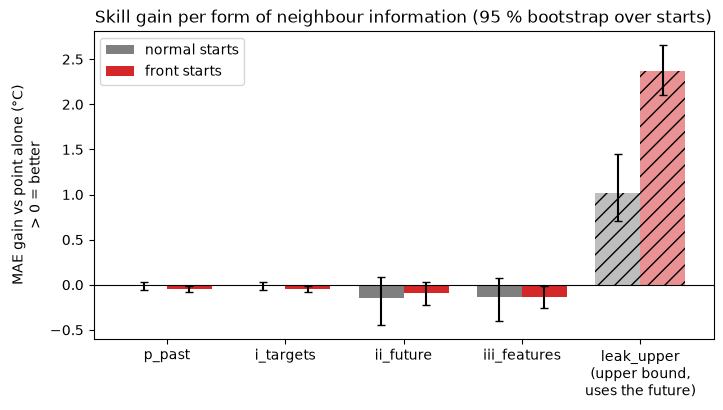

In [7]:
# skill gain per form, normal vs front starts
fig, ax = plt.subplots(figsize=(8, 4))
g = gain[(gain.form != "base") & (gain.starts != "all")]
forms = [f for f in FORMS if f != "base"]
for k, (label, color) in enumerate([("normal", "tab:gray"), ("front", "tab:red")]):
    d = g[g.starts == label].set_index("form").loc[forms]
    x = np.arange(len(forms)) + (k - 0.5) * 0.38
    bars = ax.bar(
        x, d.gain, 0.38, yerr=[d.gain - d.gain_lo, d.gain_hi - d.gain], color=color, label=f"{label} starts", capsize=3
    )
    bars[forms.index("leak_upper")].set_hatch("//")
    bars[forms.index("leak_upper")].set_alpha(0.5)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(
    range(len(forms)), [f if f != "leak_upper" else "leak_upper\n(upper bound,\nuses the future)" for f in forms]
)
ax.set(
    ylabel="MAE gain vs point alone (°C)\n> 0 = better",
    title="Skill gain per form of neighbour information (95 % bootstrap over starts)",
)
ax.legend()
fig.savefig(RESULTS / "skill_gain.png", dpi=150, bbox_inches="tight")

<a id="h1"></a>
### 8.1 · H1: past-only channels are ignored

*Form: `p_past`. Back to the hypotheses: [section 3](#3-·-Hypothesis-and-what-would-count-as-an-answer).*

In [ ]:
# H1: past-only channels (p_past) - gain per start type, then gradient and hidden-state ratio against the control
display(gain[gain.form == "p_past"].round(3))
cmp.loc[["p_past"]].round(4)

,form,starts,n,mae,gain,gain_lo,gain_hi,coverage
3,p_past,all,420,2.756,-0.035,-0.061,-0.009,0.639
4,p_past,normal,120,1.686,-0.009,-0.054,0.026,0.802
5,p_past,front,300,3.183,-0.046,-0.076,-0.013,0.574


,gain,gain_lo,gain_hi,nbr_ctx,nbr_future,h11,nbr_ctx_vs_null,nbr_future_vs_null,h11_vs_null
form,,,,,,,,,
p_past,-0.0352,-0.0607,-0.0094,0.2827,NaN,0.0163,1.232,NaN,1.0476


**Verdict:** Confirmed. Past-only neighbour channels are ignored.

**Evidence:**
- Technique 1: the gain of `p_past` is −0.035 (95 % interval −0.061 to −0.009) on all starts and −0.046 (−0.076 to −0.013) on front starts. The forecast does not get better, it gets slightly worse.
- Technique 2: the gradient with respect to the neighbour channels is 1.23 times the control, and the last hidden state is 1.05 times the control. The model hardly reacts to them.

**What it means:** This reproduces the Phase I result: giving neighbours as past-only covariates does not help. The model is slightly sensitive to them, so "ignored" means "practically not used", not "invisible". Open: whether other forms do better (H2, H3).

<a id="h2"></a>
### 8.2 · H2: future covariates improve the forecast

*Forms: `ii_future`, `iii_features`; `leak_upper` only as the reference. Back to the hypotheses: [section 3](#3-·-Hypothesis-and-what-would-count-as-an-answer).*

In [ ]:
# H2: future covariates (ii_future, iii_features) with leak_upper as the reference
display(gain[gain.form.isin(["ii_future", "iii_features", "leak_upper"])].round(3))
cmp.loc[["ii_future", "iii_features", "leak_upper"]].round(4)

,form,starts,n,mae,gain,gain_lo,gain_hi,coverage
9,ii_future,all,420,2.829,-0.108,-0.231,0.005,0.548
10,ii_future,normal,120,1.818,-0.142,-0.445,0.086,0.688
11,ii_future,front,300,3.233,-0.095,-0.224,0.033,0.491
12,iii_features,all,420,2.853,-0.132,-0.237,-0.024,0.532
13,iii_features,normal,120,1.811,-0.135,-0.406,0.077,0.673
14,iii_features,front,300,3.269,-0.131,-0.253,-0.012,0.476
15,leak_upper,all,420,0.734,1.987,1.700,2.283,0.795
16,leak_upper,normal,120,0.659,1.018,0.705,1.454,0.838
17,leak_upper,front,300,0.763,2.375,2.098,2.658,0.777


,gain,gain_lo,gain_hi,nbr_ctx,nbr_future,h11,nbr_ctx_vs_null,nbr_future_vs_null,h11_vs_null
form,,,,,,,,,
ii_future,-0.1083,-0.2310,0.0054,0.5497,0.0731,0.0555,1.4654,1.2798,1.3116
iii_features,-0.1322,-0.2373,-0.0240,0.8902,0.0894,0.0525,1.5408,1.5725,1.3912
leak_upper,1.9868,1.6997,2.2825,1.0494,0.3537,0.0928,NaN,NaN,NaN


**Verdict:** Not confirmed. Future covariates do not improve the forecast; the model sees them but does not use them well.

**Evidence:**
- Technique 1: the gain of `ii_future` is −0.108 (−0.231 to +0.005), and on front starts −0.095 (−0.224 to +0.033), so zero is inside the interval. `iii_features` is −0.132 (−0.237 to −0.024), clearly worse. The coverage of the 0.1 to 0.9 band also drops, to 0.548 and 0.532, against 0.656 for the baseline.
- Technique 2: the gradient is 1.47 and 1.54 times the control, and the last hidden state is 1.31 and 1.39 times the control. The model moves clearly more than for past-only channels.
- Reference: `leak_upper` (the upwind values unshifted) gains +1.99 (+1.70 to +2.28). It uses data after the forecast start, so it is an upper bound and not a result.

**What it means:** This is the "seen but not used" case: the information changes the inside of the model, but not the forecast. A likely reason is the shift of at least 24 h, which removes the timing that makes upwind data useful; this is a reading, not something we tested. Limits: only 12 normal starts, so the intervals on normal days are wide.


<a id="h3"></a>
### 8.3 · H3: extra targets improve the forecast

*Form: `i_targets`, next to `p_past` (the same neighbours, given as covariates). Back to the hypotheses: [section 3](#3-·-Hypothesis-and-what-would-count-as-an-answer).*

In [ ]:
# H3: extra targets (i_targets) next to p_past
display(gain[gain.form.isin(["p_past", "i_targets"])].round(3))
cmp.loc[["p_past", "i_targets"]].round(4)

,form,starts,n,mae,gain,gain_lo,gain_hi,coverage
3,p_past,all,420,2.756,-0.035,-0.061,-0.009,0.639
4,p_past,normal,120,1.686,-0.009,-0.054,0.026,0.802
5,p_past,front,300,3.183,-0.046,-0.076,-0.013,0.574
6,i_targets,all,420,2.755,-0.035,-0.060,-0.009,0.639
7,i_targets,normal,120,1.685,-0.009,-0.053,0.026,0.802
8,i_targets,front,300,3.183,-0.045,-0.075,-0.012,0.575


,gain,gain_lo,gain_hi,nbr_ctx,nbr_future,h11,nbr_ctx_vs_null,nbr_future_vs_null,h11_vs_null
form,,,,,,,,,
p_past,-0.0352,-0.0607,-0.0094,0.2827,NaN,0.0163,1.2320,NaN,1.0476
i_targets,-0.0348,-0.0601,-0.0087,0.2836,NaN,0.0163,1.2347,NaN,1.0500


**Verdict:** Not confirmed. Extra targets do not improve the forecast.

**Evidence:**
- Technique 1: the gain of `i_targets` is −0.035 (−0.060 to −0.009), the same as `p_past`.
- Technique 2: gradient 1.23 times and last hidden state 1.05 times the control, again the same as `p_past`.

**What it means:** The model ignores the extra rows, even though the source says targets attend to each other. The numbers equal `p_past` because in both forms the point's row attends to the same four neighbour rows. Open: whether this changes with other neighbour sets or a model fine-tuned for it.


### 8.4 · One front case, all forms

*Illustration only; one case is not evidence for any hypothesis.*

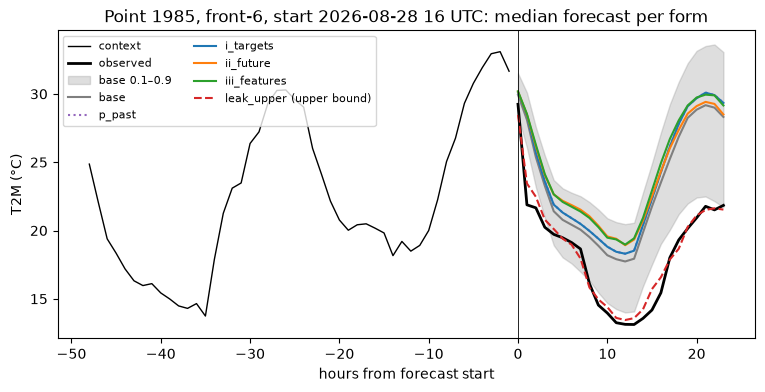

In [8]:
# forecast lines with and without neighbours, for the front case with the largest observed fall after the start
fc = cases[cases.front].copy()
fc["fall"] = [SER[c.i - 1, c.j] - np.nanmin(obs[k]) for k, c in fc.iterrows()]
k = int(fc["fall"].idxmax())
c = cases.loc[k]
hours = np.arange(-48, HORIZON)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hours[:48], SER[c.i - 48 : c.i, c.j], color="k", lw=1, label="context")
ax.plot(hours[48:], obs[k], color="k", lw=2, label="observed")
ax.fill_between(hours[48:], PRED["base"][k, 0], PRED["base"][k, 8], color="tab:gray", alpha=0.25, label="base 0.1–0.9")
styles = {
    "base": ("tab:gray", "-"),
    "p_past": ("tab:purple", ":"),
    "i_targets": ("tab:blue", "-"),
    "ii_future": ("tab:orange", "-"),
    "iii_features": ("tab:green", "-"),
    "leak_upper": ("tab:red", "--"),
}
for f in FORMS:
    col_, ls = styles[f]
    ax.plot(hours[48:], PRED[f][k, 4], color=col_, ls=ls, label=f + (" (upper bound)" if f == "leak_upper" else ""))
ax.axvline(0, color="k", lw=0.6)
ax.set(
    xlabel="hours from forecast start",
    ylabel="T2M (°C)",
    title=f"Point {c.pid}, {c.tag}, start {times[c.i]:%Y-%m-%d %H} UTC: median forecast per form",
)
ax.legend(fontsize=8, ncol=2)
fig.savefig(RESULTS / "front_case_lines.png", dpi=150, bbox_inches="tight")

## 9 · Checks

*Does the result hold on other dates, other points, other groups? What did we try to break it with?*

1. **Leakage rule:** every non-leak form must be unchanged when everything after the forecast start is overwritten.
2. **Baseline match:** `base` must reproduce the Phase I forecasts in `tirex2_forecasts.npz` (stored as float16).
3. **Same cases:** every form was scored on the same start × point cases, in the same order.
4. **Helpers vs `model.forecast`:** the gradient path (`_predict`, also with the NaN-safe scaler) gives the same quantiles as `model.forecast`, and the gradients are finite.
5. **Split by groups:** gain per point and per front/normal start, to see whether one point or one front carries the mean.

In [10]:
# 1 leakage: corrupt all data from the forecast start on and rebuild
c = cases.iloc[0].to_dict()
keep = SER.copy()
ref = {f: build(c, f) for f in FORMS}
SER[c["i"] :] = 999.0
for f in FORMS:
    t = build(c, f)
    same = all(
        np.array_equal(getattr(t, a).numpy(), getattr(ref[f], a).numpy(), equal_nan=True)
        for a in ("target", "past_covariates", "future_covariates")
        if getattr(t, a) is not None
    )
    print(
        f"leakage check {f:13s}: {'unchanged' if same else 'CHANGED'}"
        + ("  (expected: upper bound)" if f == "leak_upper" else "")
    )
    assert same or f == "leak_upper"
SER[:] = keep

# 2 baseline match against Phase I
preds = P1["preds"]  # read the array from the file once, not once per case
p1 = np.stack([preds[c.p1_k, p1_col[c.pid]] for c in cases.itertuples()]).astype(np.float32)
diff = np.abs(PRED["base"] - p1)
print(f"baseline vs Phase I: max |diff| {diff.max():.4f} °C, mean {diff.mean():.5f} °C")
assert diff.max() < 0.05, "baseline does not reproduce Phase I"

# 3 same cases for every form
assert all(len(PRED[f]) == len(cases) for f in FORMS) and set(score.columns) >= {f"mae_{f}" for f in FORMS}

# 4 gradient path == model.forecast
ts = build(c, "i_targets")
a = _predict([ts], grad=False)[0].numpy()
b = model.forecast([ts], prediction_length=HORIZON, output_type="numpy")[0]
with nan_safe_scaler():
    a2 = _predict([ts], grad=False)[0].numpy()
print(
    f"_predict vs forecast: shapes {a.shape} {b.shape}, max |diff| {np.abs(a - b).max():.2e};"
    f" with the NaN-safe scaler used for gradients: {np.abs(a2 - b).max():.2e}"
)
assert a.shape == b.shape and np.allclose(a, b, atol=1e-4) and np.allclose(a2, b, atol=1e-3)
g = gradient(build(c, "ii_future"))
assert all(
    np.isfinite(v[~np.isnan(getattr(build(c, "ii_future"), k).numpy())]).all() for k, v in g.items() if v is not None
)

# 5 gain per point and start type
per_point = score.assign(pid=cases.pid).groupby(["pid", "front"])[[f"mae_{f}" for f in FORMS]].mean()
(per_point[[f"mae_{f}" for f in FORMS[1:]]].rsub(per_point["mae_base"], axis=0)).round(3)

leakage check base         : unchanged
leakage check p_past       : unchanged
leakage check i_targets    : unchanged
leakage check ii_future    : unchanged
leakage check iii_features : unchanged
leakage check leak_upper   : CHANGED  (expected: upper bound)


baseline vs Phase I: max |diff| 0.0156 °C, mean 0.00235 °C


_predict vs forecast: shapes (5, 9, 24) (5, 9, 24), max |diff| 0.00e+00; with the NaN-safe scaler used for gradients: 0.00e+00


mae_p_past  mae_i_targets  mae_ii_future  mae_iii_features  \
pid  front                                                               
63   False       0.011          0.012         -0.169            -0.101   
     True       -0.018         -0.017          0.002            -0.032   
555  False       0.055          0.057         -0.121            -0.091   
     True       -0.075         -0.075         -0.166            -0.153   
928  False      -0.001         -0.000         -0.246            -0.201   
     True       -0.054         -0.054         -0.204            -0.240   
1455 False      -0.019         -0.018          0.309             0.260   
     True        0.001          0.001         -0.167            -0.192   
1487 False      -0.003         -0.002         -0.051            -0.034   
     True       -0.062         -0.060         -0.124            -0.114   
1508 False       0.002          0.003         -0.209            -0.297   
     True       -0.043         -0.043         -0.118            -0.133   
1985 False       0.017          0.017         -0.214            -0.139   
     True       -0.070         -0.069         -0.139            -0.225   
3022 False      -0.050         -0.051         -0.144            -0.135   
     True       -0.013         -0.013         -0.099            -0.163   
3198 False      -0.078         -0.079         -0.255            -0.253   
     True       -0.051         -0.050          0.007            -0.024   
3281 False      -0.029         -0.029         -0.319            -0.355   
     True       -0.070         -0.070          0.058            -0.035   

            mae_leak_upper  
pid  front                  
63   False           0.827  
     True            1.539  
555  False           1.026  
     True            2.278  
928  False           1.346  
     True            2.227  
1455 False           0.456  
     True            1.878  
1487 False           0.862  
     True            2.779  
1508 False           0.650  
     True            2.482  
1985 False           1.053  
     True            2.763  
3022 False           1.200  
     True            2.625  
3198 False           1.335  
     True            2.583  
3281 False           1.421  
     True            2.592

## 10 · Figure decisions

| Figure | Keep / change / drop | Used for | Why |
|---|---|---|---|
| Map of the neighbours used (`map_neighbours.png`) | keep | section 5, all forms | shows which points fed each form; upwind arrows show how the wind picked them |
| Skill gain per form (`skill_gain.png`) | keep | overview, H1 to H3 | main Technique 1 result; leak bar hatched and labelled as an upper bound so it cannot be read as a result |
| Forecast lines, one front case (`front_case_lines.png`) | keep | 8.4, illustration | makes the gain (or its absence) concrete for one case; one case only, so not evidence on its own |
| Sensitivity / hidden-state table | *decide after the run* | H1 to H3 | a bar chart per block if the forms differ by block |

## 11 · What it means

**Answer to the question.** In our setup, no form of neighbour information improved the forecast. The model reacts to some of them, but it does not turn that into better predictions.
- **Can neighbours change the forecast?** Only a little, and not for the better. The change in the forecast was a small loss (−0.035 to −0.132 °C MAE).
- **In which form?** Past-only channels and extra targets are practically ignored (hidden state 1.05× the control). Future covariates are seen (1.3× to 1.4×) but do not help.
- **What does the model do with them?** It reads the future covariates and changes its inside, but the forecast gets slightly worse and the band coverage drops (0.548 and 0.532 against 0.656).

**Which form gets past the "ignores neighbours" behaviour from Phase I?** None. All three hypotheses fail: H1 holds (past-only channels are ignored), H2 and H3 are not confirmed ([H1](#h1) · [H2](#h2) · [H3](#h3)).

**Is the effect limited to front starts?** There is no gain to limit. The real forms are as bad or slightly worse on front starts (for example `p_past` −0.046, against −0.009 on normal starts). Only the leakage reference gains more on fronts (+2.38) than on normal days (+1.02), which says that the neighbours' real values matter most at fronts.

**How far below the upper bound is the best real form?** About 2 °C of MAE. `leak_upper` gains +1.99 and the best real form (`p_past` and `i_targets`) −0.035. The shift of at least 24 h removes the advance warning that the neighbours could give. This gap is also a limit of the comparison: the unshifted neighbours are 15 km away and nearly contain the answer, so the number shows what is possible, not what the model understands about how the weather moves.

**Seen but not used?** Yes for H2 (`ii_future`, `iii_features`): states and gradients clearly above the control, no gain. No for H1 and H3: they barely move.

**What `leak_upper` adds.** With the real future values, the model does use the covariates (gain +1.99). So the null results are not a mistake in how the inputs are passed. The model can use future covariates when they contain the answer.

**What is still open.**
- Why the shifted covariates do not help (the 24 h shift is a likely reason, but we did not test it).
- Shorter shifts, which would be a leak for a 24 h forecast but fair for shorter horizons.
- Only 12 normal starts and 10 points, so the intervals on normal days are wide.


### Further ideas (not run)

Ideas for new experiments that follow from the results above. None of them has been run yet; each one that is run would get its own hypothesis (H4, H5, …) and verdict cell in section 8.

| # | Idea | What it tests | What we would do |
|---|---|---|---|
| 1 | **Shift sweep** | Does the 24 h shift remove the timing that makes upwind data useful? | Run `ii_future` with shifts of 0, 3, 6, 12, 18 and 24 h and plot gain against shift. Shifts below 24 h leak for a 24 h forecast, so mark them, and also score the matching shorter horizon (for example a 6 h forecast with a 6 h shift, which is fair). |
| 2 | **Shuffled-neighbour control** | Does the model react to the information, or only to "something extra"? | Give the future covariates of a *random* point at the same time. If gain and movement are the same, the information does not matter. |
| 3 | **Synthetic front** | Can the model use a neighbour at all, in the cleanest case? | Build a series where a cold step moves from the upwind point to the target after a known delay. If it fails here, it cannot do it on real data; if it works, the real data is the problem. |
| 4 | **Where does the signal die?** | At which depth does the model discard the neighbour information? | Compare the hidden-state difference block by block (`h0` to `h11`) for the H2 forms against the control. Uses the sensitivity table we already have. |
| 5 | **Bias or noise?** | Is the loss of the H2 forms a shifted mean or noisier forecasts? | Split the error into mean error and spread. A shifted mean could be corrected afterwards. |
| 6 | **Front starts only** | Do the shift-sweep results hold on cold fronts, which is what the question is about? | Repeat idea 1 on the 30 front starts only. |

## 12 · What did not work

*Dead ends and negative results. They are part of the record.*

**1 · Past-only channels (`p_past`)**
- *Tried:* neighbours as past covariates, as in Phase I (Exp 3, 4).
- *Happened:* no gain (−0.035), gradient 1.23× and hidden state 1.05× the control. From the source, past covariates only run forward in time and end at the forecast start.
- *Did:* kept it as the Phase I reference for H1.

**2 · Upstream values without a shift**
- *Tried:* the upwind points as future covariates, unshifted.
- *Happened:* a gain of +1.99, which looks excellent but is leakage: those values come from after the forecast start.
- *Did:* kept only as the reference `leak_upper`, never as a result. An honest covariate must be shifted by at least the 24 h horizon, which throws away most of the advance warning.

**3 · Plain backpropagation through `predict`**
- *Tried:* gradients of the forecast with respect to the inputs.
- *Happened:* every gradient was NaN. The context is padded with NaN up to `context_len + future_len`, and the backward pass of the scaler's division and `arcsinh` multiplies by those NaN values, which reach the mean and scale and from there every hour.
- *Did:* a NaN-safe copy of `Scaler.scale`, used only for gradients (same forward values, checked in section 9).

**4 · Neighbours as separate batch entries**
- *Tried:* not run (as in `run_forecasts.py`). From the source, separate entries are in different groups and never mix, so the result would be the same as `base`.

**5 · No form helped (negative result)**
- Extra targets (`i_targets`) behave exactly like `p_past`, and the shifted future covariates are slightly worse than the baseline. We expected at least H2 or H3 to work; neither did.